# 1 · The keynote catalogue

Every row of `data/catalog/events.csv` is one keynote: when it started (with its IANA time
zone, because the event day depends on whether the market was still open), whether a live
audience was present, and which YouTube video carries the full broadcast audio. The
catalogue was researched company by company and validated by `applause catalog`
(`src/unpacked_applause/catalog.py`); manual decisions are listed in
`data/catalog/curation_log.md`.

In [1]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from unpacked_applause.config import FIGURES, PROCESSED, TABLES
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
import duckdb
from unpacked_applause.catalog import load_events
events = load_events()
con = duckdb.connect()
con.register("events", events.assign(date_local=events["date_local"].dt.date))
con.execute(open("../sql/coverage.sql").read()).df()

,company,keynotes,with_video,live,hybrid,virtual,first_event,last_event,median_video_min
0,apple,55,55,35,0,20,2010-01-27,2026-06-08,93.0000
1,microsoft,51,46,38,0,13,2011-09-13,2026-06-02,73.0000
2,samsung,42,39,31,0,11,2010-02-14,2026-07-22,65.0000
3,nvidia,42,34,34,0,8,2010-01-07,2026-06-01,104.0000
4,tesla,40,39,39,1,0,2011-10-01,2026-05-20,49.0000
5,amd,38,37,24,4,10,2015-06-03,2026-07-23,74.0000
6,google,34,34,30,2,2,2010-05-19,2026-08-12,90.0000
7,meta,22,22,17,1,4,2013-01-15,2025-09-17,89.0000
8,amazon,21,21,17,1,3,2012-09-06,2025-12-02,114.0000


## When do keynotes happen relative to the trading day?

`t0` is the first session whose close is after the keynote start. Apple, Google and
Microsoft usually present at 10:00 Pacific, i.e. during US trading hours, so the reaction
starts the same day; Tesla presents in the evening and Samsung's Unpacked is overnight in
Seoul, so their `t0` is the next session.

In [3]:
study = pd.read_parquet(PROCESSED / "event_study.parquet")
ev = events.merge(study[["event_id", "t0", "days_to_t0"]], on="event_id", how="left")
ev["t0_same_day"] = ev["days_to_t0"] == 0
ev.groupby("company")["t0_same_day"].mean().rename("share with t0 = keynote day").to_frame()

,share with t0 = keynote day
company,
amazon,1.0000
amd,0.7895
apple,1.0000
google,0.9706
meta,0.9545
microsoft,0.9216
nvidia,0.8571
samsung,0.0476
tesla,0.5500


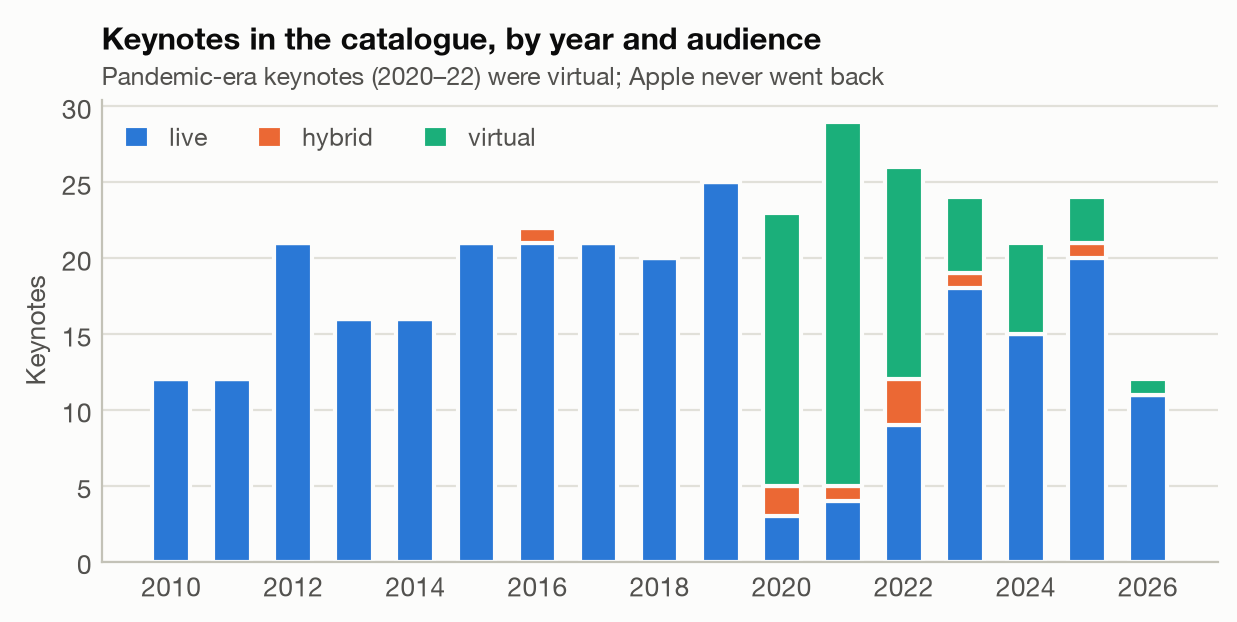

In [4]:
display(Image(filename=str(FIGURES / "coverage_by_year.png")))

In [5]:
events.groupby(["company", "audience"]).size().unstack(fill_value=0)

audience,hybrid,live,virtual
company,,,
amazon,1,17,3
amd,4,24,10
apple,0,35,20
google,2,30,2
meta,1,17,4
microsoft,0,38,13
nvidia,0,34,8
samsung,0,31,11
tesla,1,39,0
